# **EEG preporcessing**

In [8]:
# ✅ Step 0: Install MNE (if not already installed)
!pip install mne --quiet


In [9]:

# ✅ Step 1: Import required libraries
import mne
import matplotlib.pyplot as plt


In [15]:

# ✅ Step 2: Read EEG data
# Example: Reading a sample .edf file from MNE datasets
# You can also use .set, .bdf, .fif, .vhdr, etc.
from pathlib import Path

# ✅ Use pathlib Path joining
# sample_data = mne.datasets.sample.data_path()
# raw_file = sample_data / 'MEG' / 'sample' / 'sample_audvis_raw.fif'
raw_file = 'F:/EEG_procesing_workshop/EEG_Python/codes/S001R01.edf'
# ✅ Load the raw EEG/MEG data
# raw = mne.io.read_raw_fif(raw_file, preload=True)
raw = mne.io.read_raw_edf(raw_file, preload=True)
raw.plot(title="Raw EEG Data", show=True)

# ✅ Step 3: Info - How to read other file types
# mne.io.read_raw_edf('file.edf')
# mne.io.read_raw_brainvision('file.vhdr')
# mne.io.read_raw_bdf('file.bdf')
# mne.io.read_raw_eeglab('file.set')
# mne.io.read_raw_fif('file.fif')




Extracting EDF parameters from F:\EEG_procesing_workshop\EEG_Python\codes\S001R01.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 9759  =      0.000 ...    60.994 secs...


AttributeError: 'Axes' object has no attribute '_axes_class'

In [ ]:
# Print the entire info (may be long)
print("Sampling rate:", raw.info['sfreq'])
print("Channels:", raw.info['ch_names'])
print("Number of channels:", raw.info['nchan'])

Sampling rate: 600.614990234375
Channels: ['MEG 0113', 'MEG 0112', 'MEG 0111', 'MEG 0122', 'MEG 0123', 'MEG 0121', 'MEG 0132', 'MEG 0133', 'MEG 0131', 'MEG 0143', 'MEG 0142', 'MEG 0141', 'MEG 0213', 'MEG 0212', 'MEG 0211', 'MEG 0222', 'MEG 0223', 'MEG 0221', 'MEG 0232', 'MEG 0233', 'MEG 0231', 'MEG 0243', 'MEG 0242', 'MEG 0241', 'MEG 0313', 'MEG 0312', 'MEG 0311', 'MEG 0322', 'MEG 0323', 'MEG 0321', 'MEG 0333', 'MEG 0332', 'MEG 0331', 'MEG 0343', 'MEG 0342', 'MEG 0341', 'MEG 0413', 'MEG 0412', 'MEG 0411', 'MEG 0422', 'MEG 0423', 'MEG 0421', 'MEG 0432', 'MEG 0433', 'MEG 0431', 'MEG 0443', 'MEG 0442', 'MEG 0441', 'MEG 0513', 'MEG 0512', 'MEG 0511', 'MEG 0523', 'MEG 0522', 'MEG 0521', 'MEG 0532', 'MEG 0533', 'MEG 0531', 'MEG 0542', 'MEG 0543', 'MEG 0541', 'MEG 0613', 'MEG 0612', 'MEG 0611', 'MEG 0622', 'MEG 0623', 'MEG 0621', 'MEG 0633', 'MEG 0632', 'MEG 0631', 'MEG 0642', 'MEG 0643', 'MEG 0641', 'MEG 0713', 'MEG 0712', 'MEG 0711', 'MEG 0723', 'MEG 0722', 'MEG 0721', 'MEG 0733', 'MEG 0732

In [ ]:
# ✅ Step 4: Print shape of data
data, times = raw.get_data(return_times=True)
print("Data shape (channels, timepoints):", data.shape)


Data shape (channels, timepoints): (376, 166800)


NOTE: pick_types() is a legacy function. New code should use inst.pick(...).


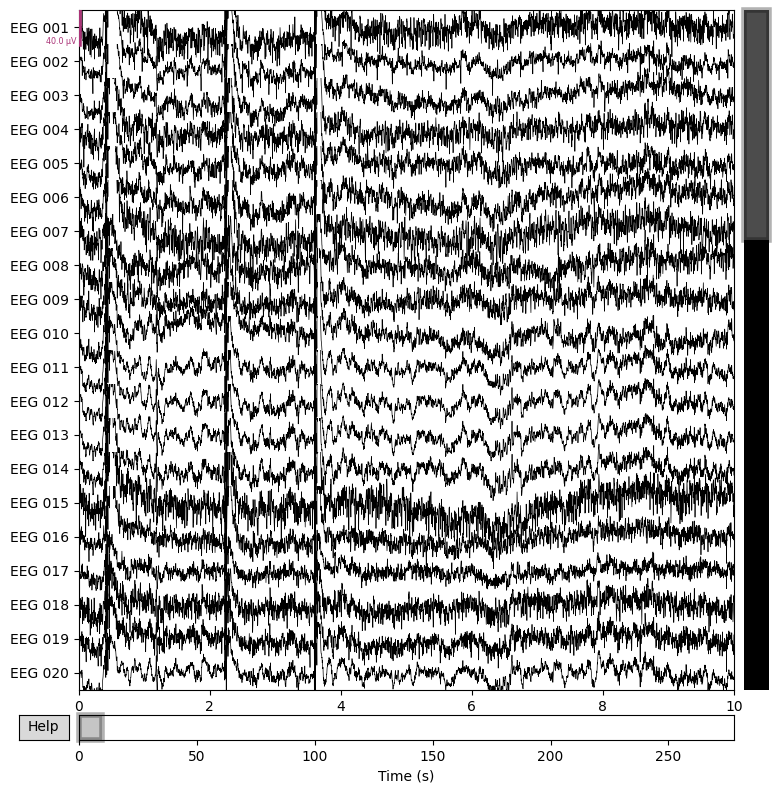

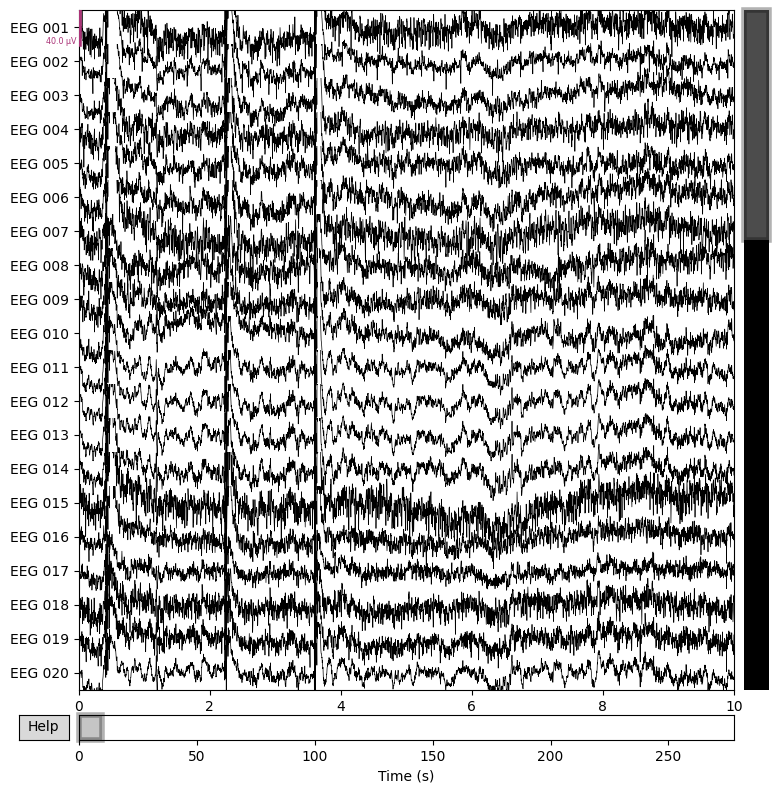

In [ ]:
# Pick only EEG channels
raw.pick_types(meg=False, eeg=True)

# Plot the EEG data
raw.plot(title="EEG Channels Only")

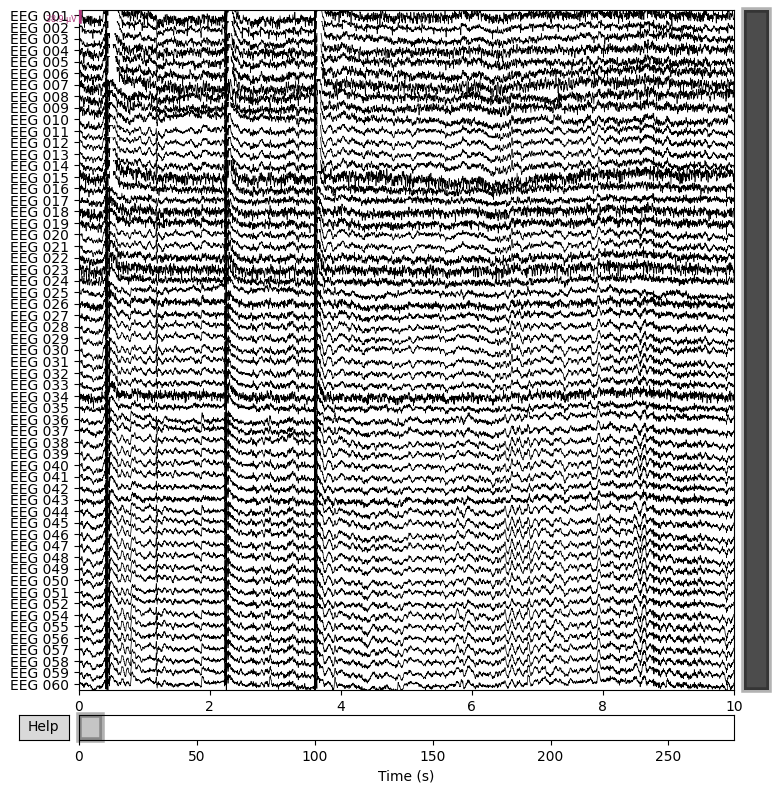

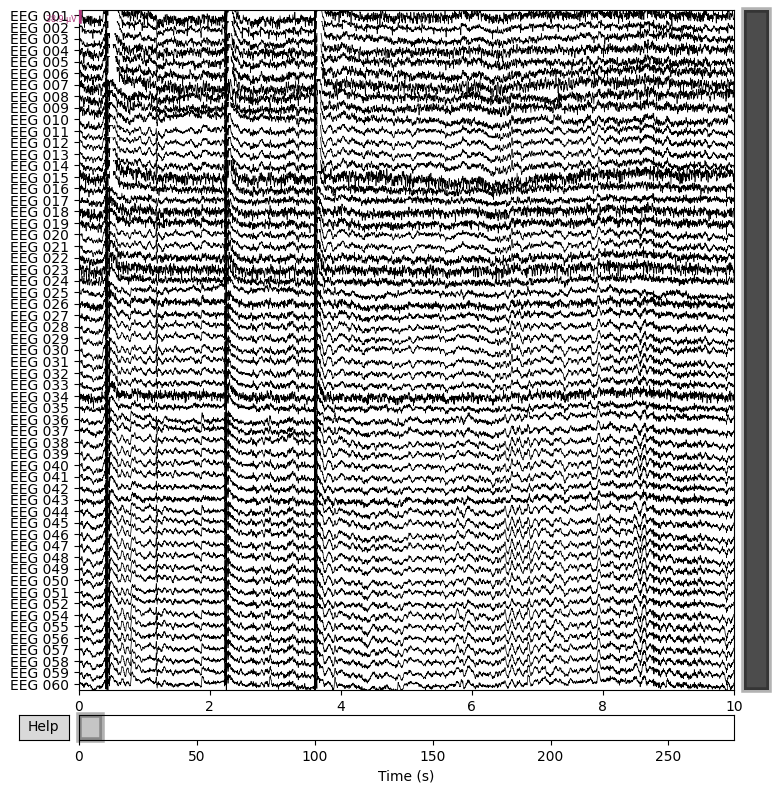

In [ ]:
raw.plot(n_channels=59, scalings='auto', title='All EEG Channels')

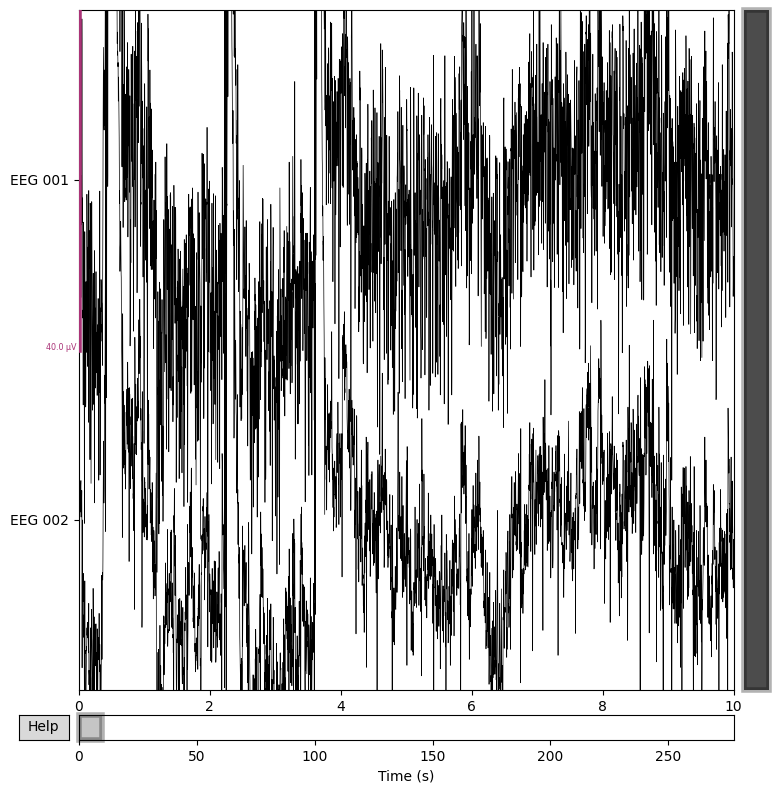

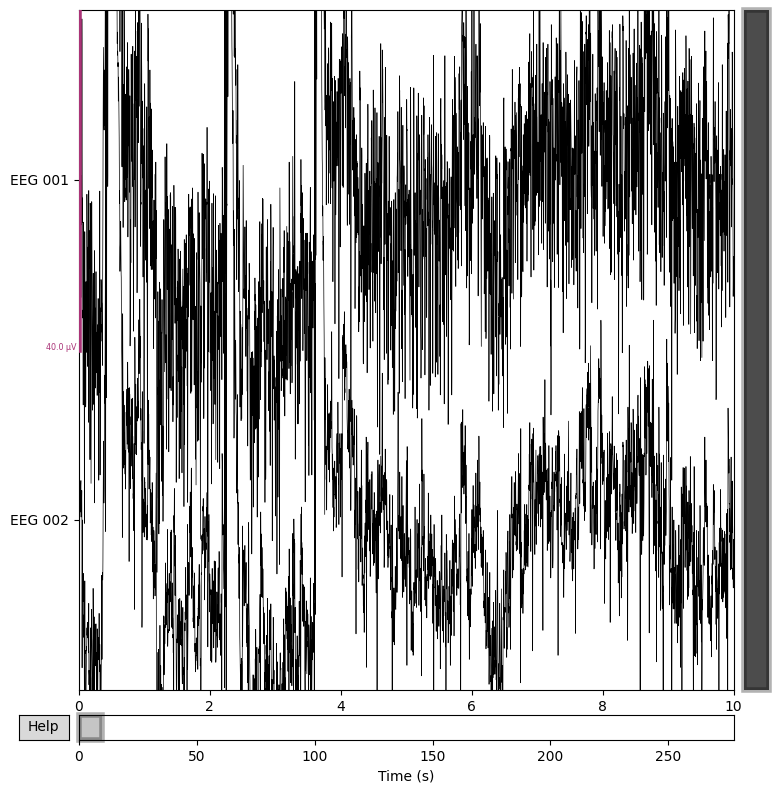

In [ ]:
raw.plot(picks=['EEG 001', 'EEG 002'])

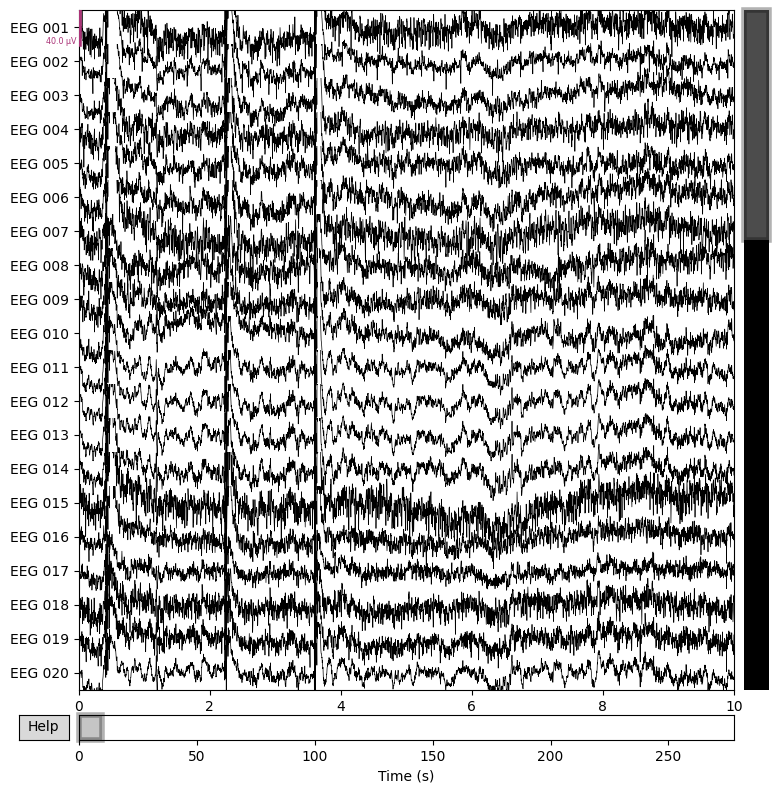

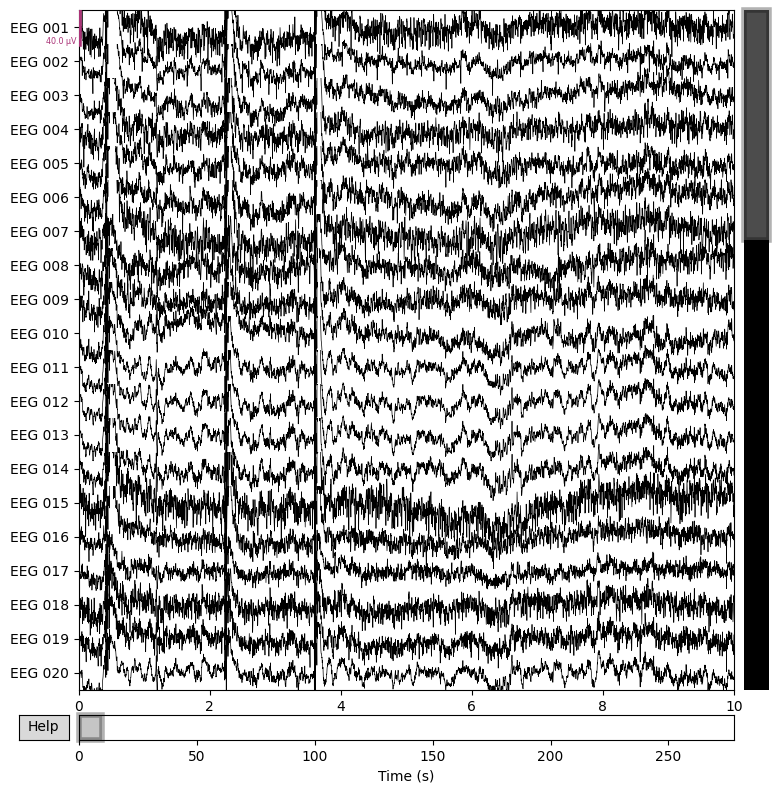

In [ ]:
raw.plot(duration=10)  # show 10 seconds per window

In [ ]:

# ✅ Step 5: Remove unwanted channels (e.g., ECG, EOG, MEG)
channels_to_drop = ['EOG 061', 'EOG 062']  # Replace with your own list
raw.drop_channels([ch for ch in channels_to_drop if ch in raw.ch_names])


<Raw | sample_audvis_raw.fif, 59 x 166800 (277.7 s), ~78.0 MiB, data loaded>

In [ ]:

# ✅ Step 6: Re-reference (e.g., average reference)
raw.set_eeg_reference('average')


EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.


<Raw | sample_audvis_raw.fif, 59 x 166800 (277.7 s), ~78.0 MiB, data loaded>

In [ ]:

# ✅ Step 7: Downsample (resample)
# raw.resample(128, npad="auto")  # downsample to 128 Hz



In [ ]:
# ✅ Step 8: Remove / select time range (crop)
# E.g., keep data from 100 to 200 seconds only
raw.crop(tmin=100, tmax=200)


<Raw | sample_audvis_raw.fif, 59 x 12801 (100.0 s), ~8.7 MiB, data loaded>

In [ ]:

# ✅ Step 9: Remove DC offset (zero-mean)
raw._data -= raw._data.mean(axis=1, keepdims=True)



NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
Effective window size : 16.000 (s)
Plotting power spectral density (dB=True).


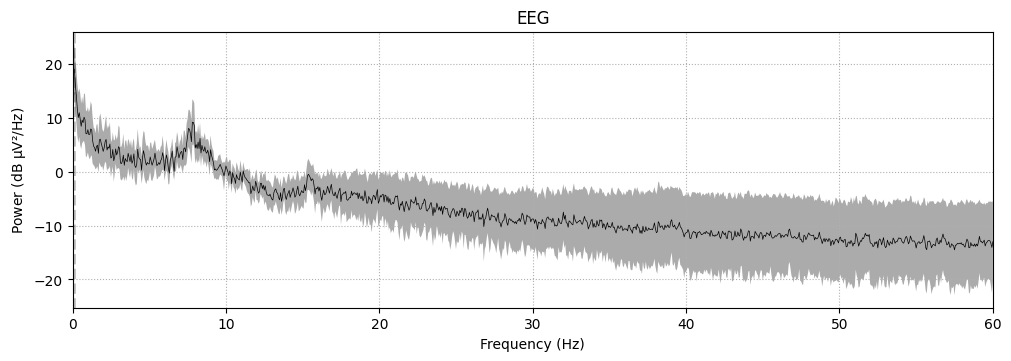

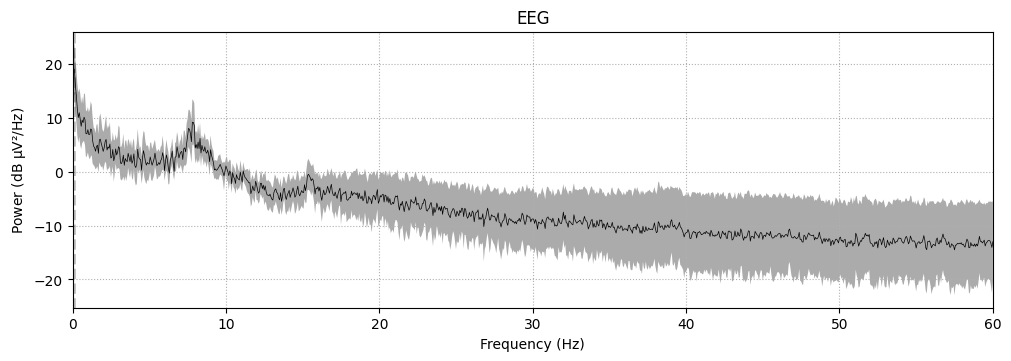

In [ ]:
# ✅ Step 10: Power spectrum before filtering
raw.plot_psd(fmax=60, average=True, show=True, spatial_colors=False)



Filtering raw data in 1 contiguous segment
Setting up low-pass filter at 30 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal lowpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Upper passband edge: 30.00 Hz
- Upper transition bandwidth: 7.50 Hz (-6 dB cutoff frequency: 33.75 Hz)
- Filter length: 57 samples (0.445 s)

NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
Effective window size : 16.000 (s)
Plotting power spectral density (dB=True).


[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  59 out of  59 | elapsed:    0.1s finished


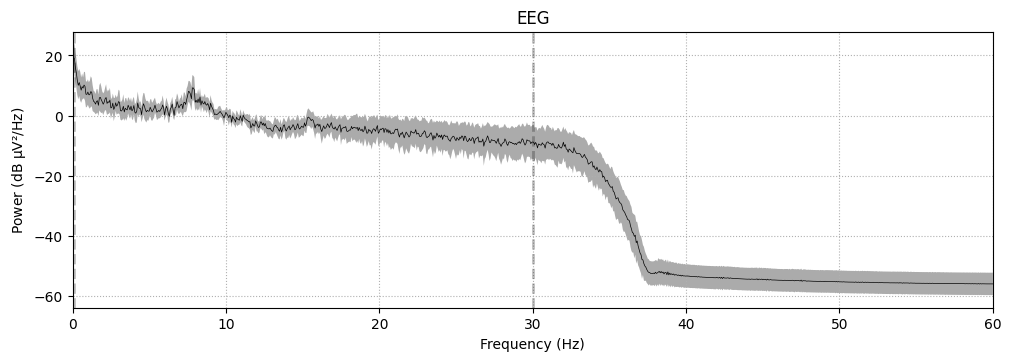

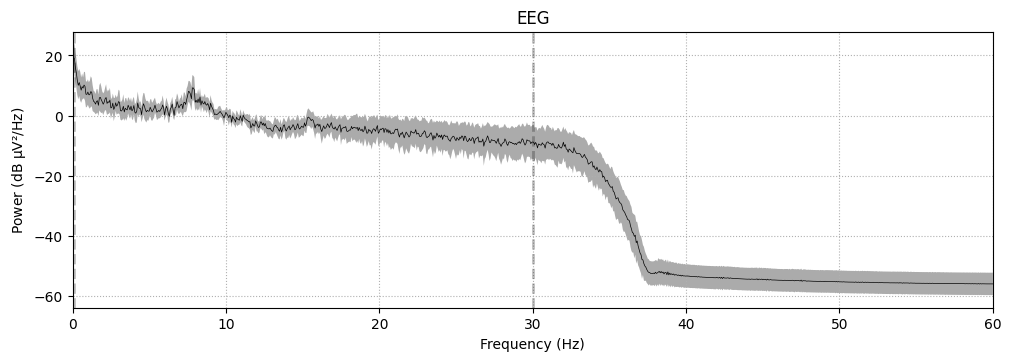

In [ ]:
# ✅ Step 11: Low-pass filter (e.g., below 30 Hz)
raw_low = raw.copy().filter(None, 30, fir_design='firwin')
raw_low.plot_psd(fmax=60, average=True, show=True, spatial_colors=False)



Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Filter length: 423 samples (3.305 s)

NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
Effective window size : 16.000 (s)
Plotting power spectral density (dB=True).


[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  59 out of  59 | elapsed:    0.0s finished


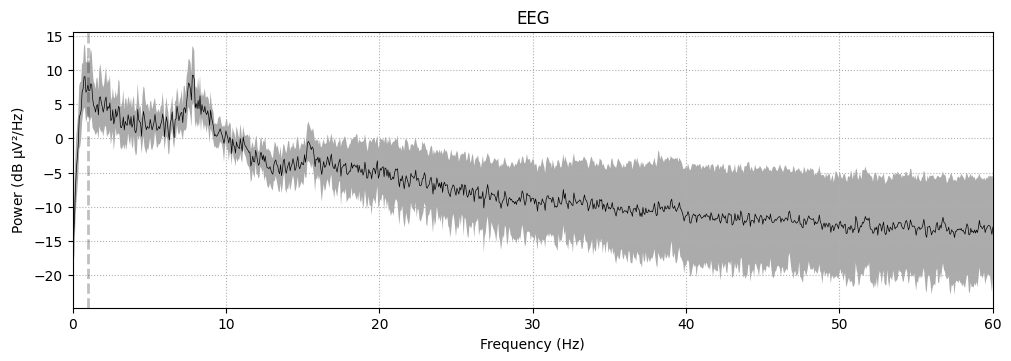

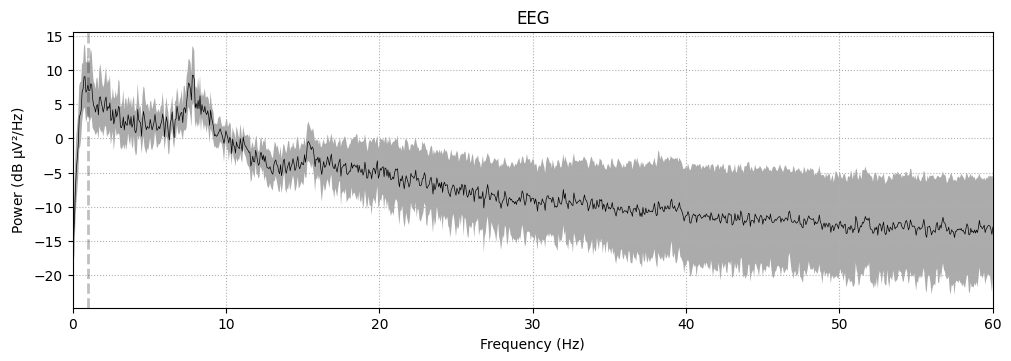

In [ ]:
# ✅ Step 12: High-pass filter (e.g., above 1 Hz)
raw_high = raw.copy().filter(1, None, fir_design='firwin')
raw_high.plot_psd(fmax=60, average=True, show=True, spatial_colors=False)



Filtering raw data in 1 contiguous segment
Setting up band-stop filter from 49 - 51 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 49.38
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 49.12 Hz)
- Upper passband edge: 50.62 Hz
- Upper transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 50.88 Hz)
- Filter length: 845 samples (6.602 s)

NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().


[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  59 out of  59 | elapsed:    0.2s finished


Effective window size : 16.000 (s)
Plotting power spectral density (dB=True).


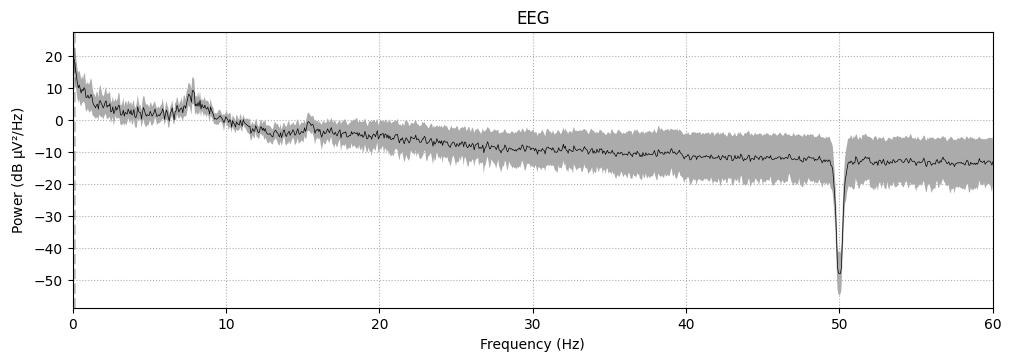

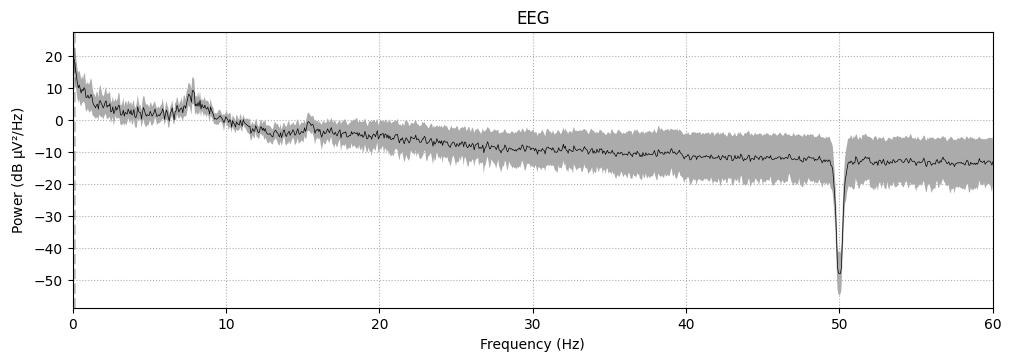

In [ ]:
# ✅ Step 13: Notch filter (e.g., remove 50/60 Hz line noise)
raw_notch = raw.copy().notch_filter(freqs=[50], fir_design='firwin')
raw_notch.plot_psd(fmax=60, average=True, show=True, spatial_colors=False)


In [ ]:

# ✅ Optional: Save preprocessed file
raw.save("preprocessed_raw.fif", overwrite=True)

Writing /content/preprocessed_raw.fif
Closing /content/preprocessed_raw.fif
[done]


[PosixPath('/content/preprocessed_raw.fif')]